# Introduction

In this assignment, you will implement SVM (Support Vector Machines) for classification.


# Data Preprocessing

Import your needed libraries in following cell.

In [1]:
# TODO: Write your code here
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from cvxopt import matrix, solvers


Load data from ```satimage``` dataset and split data to features and labels. The ```label``` column is our target variable.

In [2]:
# TODO: Write your code here
data = pd.read_csv('satimage.csv')  # Adjust filename as needed
X = data.drop('classes', axis=1).values
y = data['classes'].values

Now split data to train, validation and test parts. 60% of data should be used for train, 15% for validation and 25% for test. After that scale the data to Standard Normal Distribution using ```StandardScaler``` class from ```scikit-learn``` library.

In [3]:
# TODO: Write your code here
# Split data into train, validation, test (60-15-25)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.625, stratify=y_temp, random_state=42)

# Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

We want to train Binary SVM model for classification between labels 4 and 6. Choose corresponding datas and convert their lables to 1 and -1 respectively for 4 and 6.

In [4]:
# TODO: Write your code here
# Filter classes 4 and 5, convert labels to 1 and -1
def filter_classes(X, y):
    mask = (y == 4) | (y == 5)
    X_filtered = X[mask]
    y_filtered = y[mask]
    y_filtered = np.where(y_filtered == 4, 1, -1)
    return X_filtered, y_filtered

X_train, y_train = filter_classes(X_train, y_train)
X_val, y_val = filter_classes(X_val, y_val)
X_test, y_test = filter_classes(X_test, y_test)

# Model

Here is soft margin svm convex optimization formulation.
$$
\begin{aligned}
\text { Minimize } & \frac{1}{2}\|\mathbf{w}\|^2+C \sum_{i=1}^N \xi_i \\
\text { Subject to } & y_i\left(\mathbf{w}^T \mathbf{x}_i+b\right) \geq 1-\xi_i, \quad i=1,2, \ldots, N \\
& \xi_i \geq 0, \quad i=1,2, \ldots, N
\end{aligned}
$$
write dual of the soft margin svm optimization problem below:

`TODO: Write Here
`The dual of the soft-margin SVM optimization problem is:

$$
\begin{aligned}
\max_{\alpha} \quad & \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i,j=1}^N \alpha_i \alpha_j y_i y_j \mathbf{x}_i^T \mathbf{x}_j \\
\text{subject to} \quad & 0 \leq \alpha_i \leq C, \quad \forall i \\
& \sum_{i=1}^N \alpha_i y_i = 0
\end{aligned}
$$

Now you should write this optimization problem in standard Quadratic Program (QP) form and use a QP solver to find optimal answer. Here is General form of a QP:
$$
\begin{aligned}
\text { Minimize } & \frac{1}{2} x^TPx + q^Tx + r \\
\text { Subject to } & Gx \leq h \\
& Ax = b
\end{aligned}
$$

Complete functions below and use ```cvxopt``` library which is a common library for solving QPs. Note that you can't use ```scikit-learn``` library.


In [5]:
def soft_margin_svm(X, y, C):
    n_samples, n_features = X.shape
    y = y.reshape(-1, 1) * 1.0  # Ensure float type
    
    # QP parameters for dual problem
    K = np.dot(X, X.T)
    P = matrix(np.outer(y, y) * K)
    q = matrix(-np.ones(n_samples))
    G = matrix(np.vstack((-np.eye(n_samples), np.eye(n_samples))))
    h = matrix(np.hstack((np.zeros(n_samples), np.ones(n_samples) * C)))
    A = matrix(y.reshape(1, -1))
    b = matrix(0.0)
    
    # Solve QP
    solvers.options['show_progress'] = False
    solution = solvers.qp(P, q, G, h, A, b)
    alphas = np.array(solution['x']).flatten()
    
    # Extract support vectors
    sv_mask = alphas > 1e-5
    support_vectors = X[sv_mask]
    support_vector_labels = y[sv_mask]
    support_vector_alphas = alphas[sv_mask]
    
    return support_vectors, support_vector_labels, support_vector_alphas

In [6]:
C = 1.0
support_vectors, support_vector_labels, support_vector_alphas = soft_margin_svm(X_train, y_train, C)


In [7]:
def predict_labels(X_test, support_vectors, sv_labels, sv_alphas):
    # Compute weight vector w
    # Reshape sv_alphas and sv_labels to column vectors for broadcasting
    w = np.sum((sv_alphas.reshape(-1, 1) * sv_labels.reshape(-1, 1)) * support_vectors, axis=0)
    
    # Compute bias b
    b = np.mean(sv_labels - np.dot(support_vectors, w))
    
    # Predict labels
    y_pred = np.sign(np.dot(X_test, w) + b)
    return y_pred

In [8]:
y_pred = predict_labels(np.array(X_test), support_vectors, support_vector_labels, support_vector_alphas)

# Evaluation




Compute accuracy, balanced accuracy and plot confusion matrix of your trained model using ```Seaborn.heatmap()``` function. Use case of balanced accuracy is when dealing with imbalanced data, i.e. when one of the target classes appears a lot more than the other and it is defined by average of recall of classes. Confusion matrix is a $k\times k$ (k is number of classes) matrix which cell ij is showing that number of data points labeld i which predicted j. For more detail of evaluation metrics you can see [here](https://neptune.ai/blog/balanced-accuracy).

You may use ```scikit-learn``` library to compute these metrics.

In [9]:
def evaluate(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
    print("Confusion Matrix:\n", cm)
    return accuracy, balanced_accuracy, cm


_, _, confusion_mat = evaluate(y_test, y_pred)

Accuracy: 0.9610
Balanced Accuracy: 0.9606
Confusion Matrix:
 [[171   6]
 [  7 149]]


<Axes: >

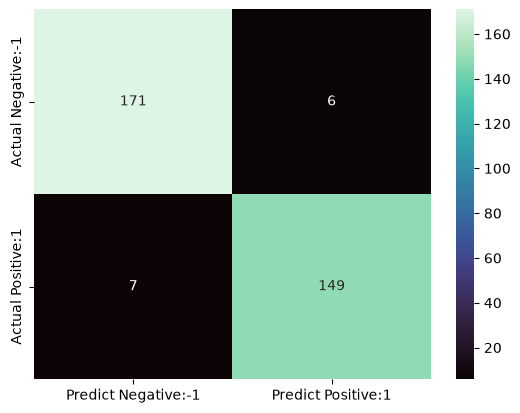

In [10]:
cm_matrix = pd.DataFrame(data=confusion_mat, columns=['Predict Negative:-1', 'Predict Positive:1'],
                                 index=['Actual Negative:-1', 'Actual Positive:1'])

sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')

# Fine-tunning

like what you did before, implement Soft Margin SVM but now use rbf kernel. To determine rbf $\gamma$ parameter use validation datas and find best(best by balanced accuracy) $\gamma$ between 0.001 , 0.01, 1, 10, 100. Note that you can't use ```scikit-learn``` library here.

In [11]:
def rbf(x1, x2, gamma=1):
    return np.exp(-gamma * np.linalg.norm(x1 - x2)**2)

def soft_margin_svm_rbf(X, y, C, gamma=1):
    n_samples = X.shape[0]
    y = y.reshape(-1, 1) * 1.0
    
    # Compute RBF kernel matrix
    K = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            K[i, j] = rbf(X[i], X[j], gamma)
    
    # QP setup
    P = matrix(np.outer(y, y) * K)
    q = matrix(-np.ones(n_samples))
    G = matrix(np.vstack((-np.eye(n_samples), np.eye(n_samples))))
    h = matrix(np.hstack((np.zeros(n_samples), np.ones(n_samples) * C)))
    A = matrix(y.reshape(1, -1))
    b = matrix(0.0)
    
    solution = solvers.qp(P, q, G, h, A, b)
    alphas = np.array(solution['x']).flatten()
    
    sv_mask = alphas > 1e-5
    return X[sv_mask], y[sv_mask], alphas[sv_mask]

In [12]:
gammas = [0.001, 0.1, 1, 10, 100]  # Corrected gamma values (typo fixed)
best_gamma = None
best_ba = -np.inf

for gamma in gammas:
    # Train SVM with RBF kernel and current gamma
    support_vectors, sv_labels, sv_alphas = soft_margin_svm_rbf(X_train, y_train, C=1.0, gamma=gamma)
    
    # Predict on validation set
    y_val_pred = predict_labels(X_val, support_vectors, sv_labels, sv_alphas)
    
    # Compute balanced accuracy
    ba = balanced_accuracy_score(y_val, y_val_pred)
    
    # Update best parameters if current gamma is better
    if ba > best_ba:
        best_ba = ba
        best_gamma = gamma
        best_support_vectors = support_vectors
        best_support_vector_labels = sv_labels
        best_support_vector_alphas = sv_alphas

print(f"Best Gamma: {best_gamma}")

Best Gamma: 0.001


Accuracy: 0.9039
Balanced Accuracy: 0.9047
Confusion Matrix:
 [[158  19]
 [ 13 143]]


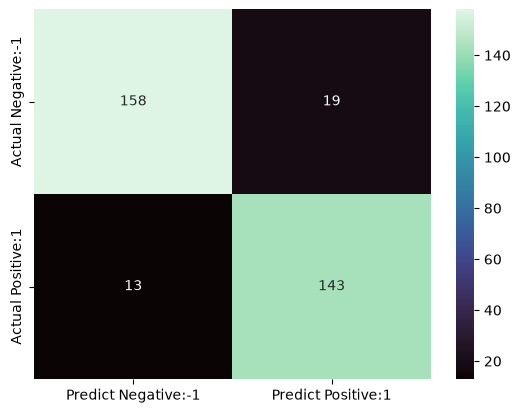

In [13]:
# Predict on test set
y_pred = predict_labels(X_test, best_support_vectors, best_support_vector_labels, best_support_vector_alphas)

# Evaluate performance
accuracy, balanced_accuracy, confusion_mat = evaluate(y_test, y_pred)

# Plot confusion matrix
cm_matrix = pd.DataFrame(data=confusion_mat, columns=['Predict Negative:-1', 'Predict Positive:1'],
                         index=['Actual Negative:-1', 'Actual Positive:1'])
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')
plt.show()

# Multiclass SVM




Now we want implement Multiclass SVM. Use ```SVC``` function with rbf kernel from ```scikit-learn``` package on all train datas (all six classes) and choose best hyperparameters for $C$ and $\gamma$ between 0.01, 0.1, 1, 10, 100. After that evaluate it with your function.

Note that in this example we had enough data to split them in train and validation but in case that we don't have enough data, ```scikit-learn``` has a built-in fast library named ```GridSearchCV()``` which can help us in hyperparameter tunning with cross validation.

In [14]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Reload original data (all classes)
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X, y, test_size=0.25, random_state=42)

# Hyperparameter grid
param_grid = {'C': [0.01, 0.1, 1, 10, 100], 'gamma': [0.01, 0.1, 1, 10, 100]}
svc = SVC(kernel='rbf')
grid_search = GridSearchCV(svc, param_grid, cv=3, scoring='balanced_accuracy')
grid_search.fit(X_train_all, y_train_all)

print(f"Best Parameters: {grid_search.best_params_}")
y_pred_all = grid_search.predict(X_test_all)
_, _, confusion_mat = evaluate(y_test_all, y_pred_all)


Best Parameters: {'C': 10, 'gamma': 0.1}
Accuracy: 0.9291
Balanced Accuracy: 0.9020
Confusion Matrix:
 [[383   1   4   0   2   0]
 [  0 178   0   1   3   0]
 [  0   0 342   7   0   5]
 [  0   4  31  87   1  25]
 [  1   1   0   0 153   4]
 [  0   0   7  11   6 351]]


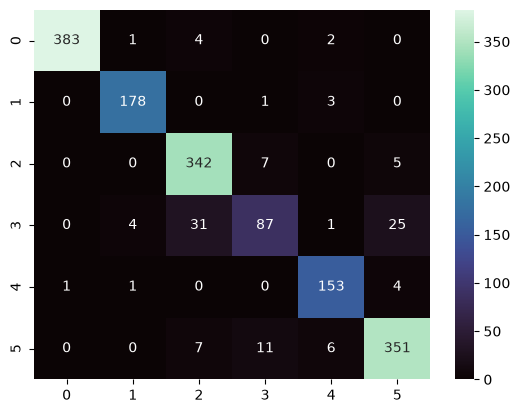

In [15]:
# Plot confusion matrix
cm_matrix = pd.DataFrame(data=confusion_mat)
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')
plt.show()

Implement Multiclass SVM from scratch without using ready functions (optional).


In [16]:
# TODO: Write your code here
import numpy as np

class MulticlassSVM:
    def __init__(self, n_classes, lambda_param=0.01, n_epochs=1000):
        self.n_classes = n_classes
        self.lambda_param = lambda_param
        self.n_epochs = n_epochs
        self.classifiers = []

    def _add_bias(self, X):
        return np.hstack([X, np.ones((X.shape[0], 1))])

    def _normalize(self, X):
        return (X - np.mean(X, axis=0)) / np.std(X, axis=0)

class BinarySVM:
    def __init__(self, lambda_param=0.01, n_epochs=1000):
        self.lambda_param = lambda_param
        self.n_epochs = n_epochs
        self.w = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        for _ in range(self.n_epochs):
            idx = np.random.permutation(n_samples)
            X_shuffled, y_shuffled = X[idx], y[idx]
            for i in range(n_samples):
                eta = 1.0 / (self.lambda_param * (i + 1))
                margin = y_shuffled[i] * np.dot(self.w, X_shuffled[i])
                if margin < 1:
                    self.w = (1 - eta * self.lambda_param) * self.w + eta * y_shuffled[i] * X_shuffled[i]
                else:
                    self.w = (1 - eta * self.lambda_param) * self.w

    def decision_function(self, X):
        return np.dot(X, self.w)
    
class MulticlassSVM(MulticlassSVM):
    def fit(self, X, y):
        X = self._normalize(X)
        X = self._add_bias(X)
        for class_idx in range(self.n_classes):
            # Create binary labels: +1 for target class, -1 otherwise
            y_binary = np.where(y == class_idx, 1, -1)
            svm = BinarySVM(self.lambda_param, self.n_epochs)
            svm.fit(X, y_binary)
            self.classifiers.append(svm)

    def predict(self, X):
        X = self._normalize(X)
        X = self._add_bias(X)
        scores = np.array([svm.decision_function(X) for svm in self.classifiers])
        return np.argmax(scores, axis=0)

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Train model
svm = MulticlassSVM(n_classes=3, lambda_param=0.01, n_epochs=1000)
svm.fit(X_train, y_train)

# Predict
y_pred = svm.predict(X_test)

# Evaluate
accuracy = np.mean(y_pred == y_test)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.46


# Different SVM Kernels

A kernel in SVM is like a tool that helps solve tricky problems. It lets us work in a space with many dimensions, making complex calculations easier. With kernels, we can deal with lots of dimensions, even an endless amount. Kernels are crucial for sorting data into groups and help spot patterns in the data we're looking at. They're especially good at tackling twisty problems with a straightforward approach.

Sometimes, finding a straight line or flat surface to divide data isn't possible, especially as we explore more dimensions. That's where different types of SVM kernels come in handy. They transform twisty, complicated data into a simpler form that's easier to separate. In this explanation, we talk about 4 popular types of these kernels. Also in following cells you can use any package.


### Linear Kernel

This is the simplest kind of kernel, typically working in one dimension. It works best when dealing with a lot of features. Linear kernels are quicker than other types.

**Formula:**

$$F(x, x_j) = sum(x, x_j)$$

Now Implement svc classifier using a linear kernel. Get the prediction and evaluate it by function which you implemented before. Also plot confusion matrix by `Seaborn`.

Accuracy: 0.8663
Balanced Accuracy: 0.8225
Confusion Matrix:
 [[384   0   3   0   3   0]
 [  3 168   0   1  10   0]
 [  1   0 332  21   0   0]
 [  1   1  34  71   2  39]
 [  8   8   0   2 122  19]
 [  0   0   7  40  12 316]]


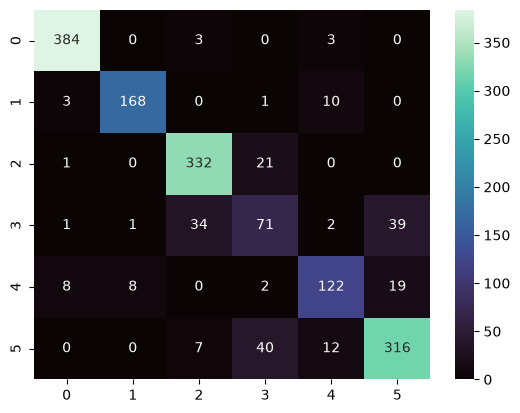

In [17]:
# TODO: Write your code here
svc_linear = SVC(kernel='linear').fit(X_train_all, y_train_all)
y_pred_all = svc_linear.predict(X_test_all)
_, _, confusion_mat = evaluate(y_test_all, y_pred_all)
# Plot confusion matrix
cm_matrix = pd.DataFrame(data=confusion_mat)
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')
plt.show()

### Gaussian RBF kernel

This kernel is a favorite choice in SVM, especially for data that doesn't line up straight. It's great for sorting data when you don't know much about it beforehand.

**Formula:**

$$F(x, x_j) = \exp{(-\gamma ||x - xj||^2)}$$

Now, configure the SVC classifier with a sigmoid kernel. Get the prediction and evaluate it by function which you implemented before. Also plot confusion matrix as previous part.

Accuracy: 0.9142
Balanced Accuracy: 0.8796
Confusion Matrix:
 [[383   1   4   0   2   0]
 [  0 179   0   1   2   0]
 [  1   0 342   8   0   3]
 [  1   2  35  77   1  32]
 [  3   1   0   0 144  11]
 [  0   0   8  14   8 345]]


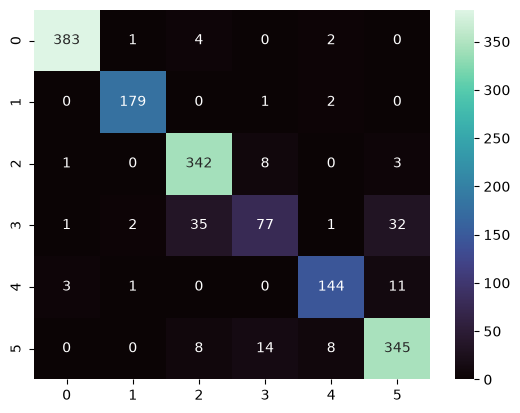

In [18]:
# TODO: Write your code here
svc_rbf = SVC(kernel='rbf', gamma=0.1).fit(X_train_all, y_train_all)
y_pred_all = svc_rbf.predict(X_test_all)
_, _, confusion_mat = evaluate(y_test_all, y_pred_all)
# Plot confusion matrix
cm_matrix = pd.DataFrame(data=confusion_mat)
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')
plt.show()

### Polynomial Kernel

This is a broader version of the linear kernel. It's not as popular because it's not as quick or precise.

**Formula:**

$$F(x, x_j) = (x.x_j+1)^d$$

Now, set up the SVC classifier using a *polynomial* kernel. Get the prediction and evaluate it by function which you implemented before. Also plot confusion matrix as previous parts.

Accuracy: 0.8725
Balanced Accuracy: 0.8427
Confusion Matrix:
 [[386   0   4   0   0   0]
 [  1 172   0   5   4   0]
 [  3   0 326  24   0   1]
 [  4   0  25  96   0  23]
 [ 14   1   0   7 117  20]
 [  0   0   8  54   7 306]]


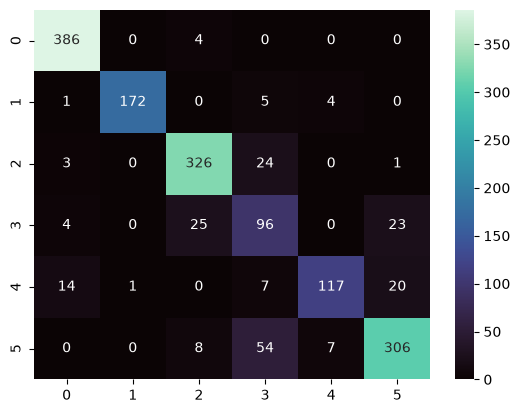

In [19]:
# TODO: Write your code here
svc_poly = SVC(kernel='poly', degree=3).fit(X_train_all, y_train_all)
y_pred_all = svc_poly.predict(X_test_all)
_, _, confusion_mat = evaluate(y_test_all, y_pred_all)
# Plot confusion matrix
cm_matrix = pd.DataFrame(data=confusion_mat)
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')
plt.show()

### Sigmoid Kernel

This is mainly chosen for use with neural networks. The kernel function acts like the activation function in a two-layer perceptron neural network model, helping to activate the neurons.

**Formula:**

$$F(x, x_j) = \tanh(α x a y + c)$$

Now, configure the SVC classifier with a sigmoid kernel. Get the prediction and evaluate it by function which you implemented before. Also plot confusion matrix as previous parts.

Accuracy: 0.7164
Balanced Accuracy: 0.6567
Confusion Matrix:
 [[303   7  13   0  67   0]
 [ 39 138   0   2   3   0]
 [  0   0 329  21   0   4]
 [  1   1  34  48  15  49]
 [ 18  25   0  33  72  11]
 [  0   0   7  55  51 262]]


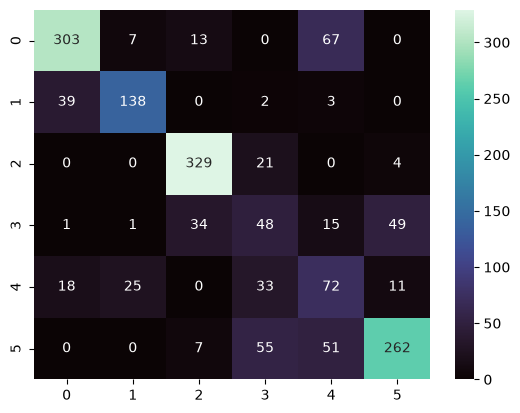

In [20]:
# TODO: Write your code here
svc_sigmoid = SVC(kernel='sigmoid').fit(X_train_all, y_train_all)
y_pred_all = svc_sigmoid.predict(X_test_all)
_, _, confusion_mat = evaluate(y_test_all, y_pred_all)
# Plot confusion matrix
cm_matrix = pd.DataFrame(data=confusion_mat)
sns.heatmap(cm_matrix, annot=True, fmt='d', cmap='mako')
plt.show()

Compare these four kernel functions with each other. What are the main advantages and disadvantages of each one?

`TODO: Write Here`
### **Kernel Comparison Summary**  
- **Linear Kernel**:  
  - **Advantages**: Fast and efficient for linearly separable data. Works well with high-dimensional features.  
  - **Disadvantages**: Fails to capture complex non-linear patterns.  

- **Gaussian RBF Kernel**:  
  - **Advantages**: Highly flexible for non-linear data. Works well even with no prior knowledge of data distribution.  
  - **Disadvantages**: Sensitive to the choice of $\gamma$ (overfitting for large $\gamma$, underfitting for small $\gamma$).  

- **Polynomial Kernel**:  
  - **Advantages**: Captures polynomial relationships between features. Generalizes the linear kernel.  
  - **Disadvantages**: Computationally expensive and less stable due to higher degrees.  

- **Sigmoid Kernel**:  
  - **Advantages**: Mimics neural network activation functions. Useful for specific use cases like binary classification.  
  - **Disadvantages**: Often underperforms compared to RBF and requires careful tuning of parameters.  